# ORCHID tutorial 06: 2D drift-diffusion and organic field-effect transistors

**Goals.** Use the 2D drift–diffusion solver (`orchid.dd2d`) to simulate an organic field-effect
transistor and compare it with the gradual-channel approximation.

### Theory
Gradual channel: $I_D/W=\dfrac{\mu C_i}{L}\left[(V_G-V_T)V_D-\tfrac12V_D^2\right]$ below pinch-off, and
$I_{sat}/W=\dfrac{\mu C_i}{2L}(V_G-V_T)^2$ above it. The 2D solver works on a non-uniform $(x,y)$ grid.
It uses Newton's method with a sparse finite-difference Jacobian built with 15-colour graph colouring.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


In [2]:
from orchid.dd2d import ofet
mu_in = 1e-6
d = ofet(mu_p=mu_in, Nx=31, ny_s=20)
VGs = np.array([-4.0, -6.0, -8.0, -10.0])
I, z = [], None
for VG in VGs:
    z = d.solve({"gate": VG, "drain": -0.2}, z0=z)
    I.append(-d.contact_current(z, {"gate": VG, "drain": -0.2}, "drain"))
slope = np.polyfit(VGs, I, 1)
mu_lin = abs(slope[0]) * d.L_ch / (d.C_i * 0.2)
VT = -slope[1] / slope[0]
print(f"linear mobility {mu_lin:.3e} (input {mu_in:.0e}), V_T = {VT:.2f} V")

linear mobility 9.726e-07 (input 1e-06), V_T = -0.08 V


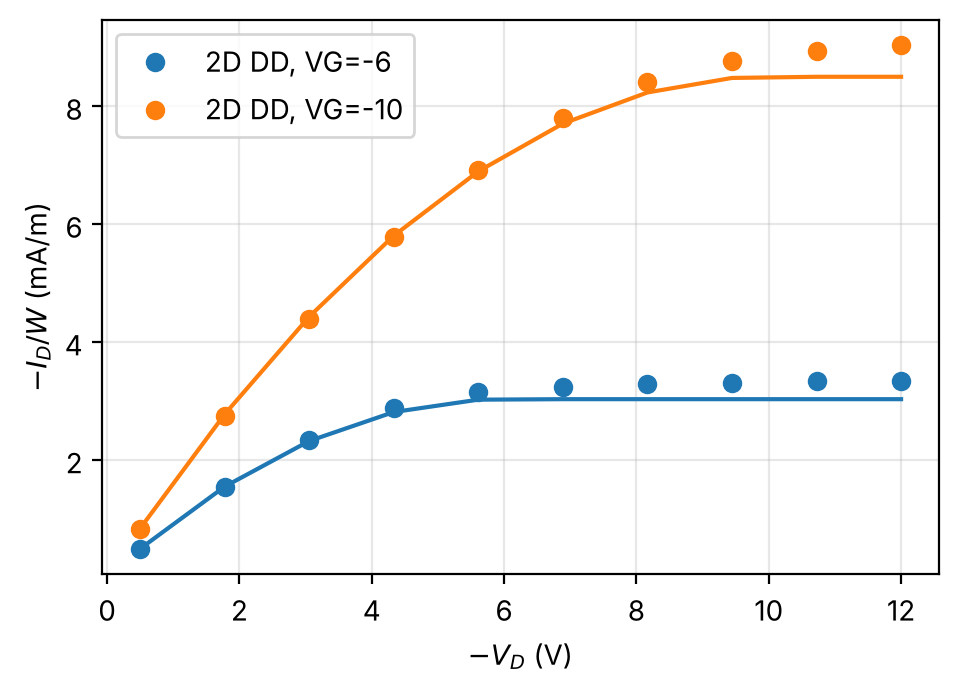

In [3]:
VDs = -np.linspace(0.5, 12, 10)
fig, ax = plt.subplots()
for VG in (-6.0, -10.0):
    z, Id = None, []
    for VD in VDs:
        z = d.solve({"gate": VG, "drain": VD}, z0=z)
        Id.append(-d.contact_current(z, {"gate": VG, "drain": VD}, "drain"))
    Vov = abs(VG - VT)
    gca = mu_in * d.C_i / d.L_ch * np.where(np.abs(VDs) < Vov, Vov * np.abs(VDs) - VDs**2 / 2, Vov**2 / 2)
    ax.plot(-VDs, np.array(Id) * 1e3, "o", label=f"2D DD, VG={VG:.0f}")
    ax.plot(-VDs, gca * 1e3, "-", c=ax.lines[-1].get_color())
ax.set_xlabel(r"$-V_D$ (V)"); ax.set_ylabel(r"$-I_D/W$ (mA/m)"); ax.legend();

**Exercise.** Double the oxide thickness `t_ox` in `ofet(...)`. What happens to $C_i$ and to the drain current?

<details><summary>Solution</summary>

$C_i=\varepsilon_0\varepsilon_{ox}/t_{ox}$ halves, so at the same overdrive the current also halves.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("06", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 06`.

In [4]:
from orchid.tutorials import quiz
quiz("06")

Quiz 06: 2D drift-diffusion and organic field-effect transistors

Q1. In the gradual-channel model, the linear-regime drain current per unit width is
    (a) q n mu V_D / L
    (b) mu C_i (V_G - V_T)^2 / (2L)
    (c) mu C_i (V_G - V_T) V_D / L
    (d) mu C_i V_D^2 / L

Q2. In saturation, the gradual-channel current is
    (a) Independent of V_G
    (b) mu C_i (V_G - V_T) V_D / L
    (c) Proportional to V_D^2
    (d) mu C_i (V_G - V_T)^2 / (2L)

Q3. Why does an OFET need a 2D solver?
    (a) 1D codes cannot handle holes
    (b) Because transport is 3D
    (c) The field has strong lateral and vertical components, and the accumulation layer is a few nm thick
    (d) To include optics

Q4. What does the 15-colour Jacobian in dd2d do?
    (a) It uses 15 Newton steps
    (b) It perturbs structurally independent unknowns together, so building the finite-difference Jacobian costs 15 residual evaluations instead of N
    (c) It solves 15 voltages at once
    (d) It uses 15 threads

Q5. V23 comp

In [5]:
# replace with your answers, e.g. "abcda"
# quiz("06", answers=".....")

<details><summary>Answer key</summary>

`cdcbb`. Run `quiz("06", answers="cdcbb")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`